# Hillstrom 邮件实验：个人指导练习展示

本文件由 Agent 从本人学习 Notebook 整理，展示本人在指导下完成的练习过程，包含参考后复现、提示后迁移与排错。既有 Python 参考实现由 Agent 编写，不能把本文件中的全部代码表述为本人独立实现。原答与 Agent 评审在原学习文件中分别保留。

## 阅读说明

- 业务问题：男装、女装邮件相对不发邮件，是否提高两周人均收入；固定毛利率和成本假设下如何判断经济价值。
- 分母：全部随机分组客户，包含零消费客户。
- 本副本保留原学习代码及 Markdown 说明；其中阶段评审按当时状态保留，当前进度见[项目状态](../PROJECT_STATE.md)。
- 仅带入原执行 90 的收入汇总表和执行 91 的区间图；其余代码输出已从本副本省略，原始行级数据预览和本机路径输出未带入。
- 省略最后的本机路径与文件时间诊断单元、空白代码单元。保留的执行编号属于此前保存记录，本轮整理没有重新运行分析；本副本未经独立环境运行验收。
- [本人已审阅的一页摘要](../reports/practice/business_summary_draft.md)、[完整精度收入结果](../reports/practice/revenue_increment_bonferroni.csv)、[独立区间图](../reports/practice/revenue_increment_bonferroni.png)。
- 原学习本为 `python_practice.ipynb`，其代码、输出和文件内容保持原样。重新运行本副本中的导出单元会写入项目 `reports/practice/`，如需实验修改，应先保护已有成果。

## 学习过程与历史评审


## P1

In [1]:
from pathlib import Path
import pandas as pd

current_dir = Path.cwd()
current_dir

In [2]:
project_root = current_dir.parent
data_path = project_root / "data" / "raw" / "hillstrom.csv"

print(project_root)
print(data_path)
print(data_path.exists())

In [3]:
df = pd.read_csv(data_path)

print(type(df))
print(df.shape)

In [4]:
print(df.columns.tolist())
df.head()

In [5]:
df.info()

In [6]:
missing_counts = df.isna().sum()
missing_counts

In [7]:
df["segment"].value_counts(dropna=False)

In [8]:
df["visit"].value_counts(dropna=False)

In [9]:
df["conversion"].value_counts(dropna=False)

In [10]:
zero_spend_count = (df["spend"] == 0).sum()
negative_spend_count = (df["spend"] < 0).sum()

print("零消费人数：", zero_spend_count)
print("负金额记录数：", negative_spend_count)

In [11]:
purchase_mismatch = (df["conversion"] == 1) != (df["spend"] > 0)

print("购买标记与消费金额不一致的记录数：", purchase_mismatch.sum())

In [12]:
purchase_without_visit = (df["conversion"] == 1) & (df["visit"] == 0)

print("购买但未访问的记录数：", purchase_without_visit.sum())

In [13]:
df[["recency", "history", "spend"]].describe()

In [14]:
zero_spend_rate = zero_spend_count / len(df)
print(f"零消费客户占比：{zero_spend_rate:.2%}")

1. 数据有多少行、多少列，分为哪三组；
2. 零消费比例是多少，为什么零消费不等于缺失；
3. 两项逐行一致性检查发现了什么，以及这些检查尚不能证明什么。



1. 数据共有 64,000 行、12 列。按照 `segment` 分为 `Womens E-Mail`、`Mens E-Mail` 和 `No E-Mail` 三个实验组。
2. 零消费客户有 63,422 人，占全部客户的 99.10%。`spend=0` 是已记录的消费金额，表示该客户在观察期内没有消费，不属于缺失值；这些客户仍然要保留在总体人数和人均消费的分母中。
3. 购买标记与消费金额不一致的记录数为 0，购买但未访问的记录数也为 0，说明 `conversion`、`spend` 和 `visit` 在这两项规则下逐行一致。这些检查只能验证相关字段的内部对应关系，不能证明三组实验前客户特征已经平衡，也不能据此判断邮件是否产生了效果。
P

## P2
业务问题是：三种邮件策略分别覆盖多少客户、带来多少访问者和购买者、产生多少收入，以及各组的访问率、购买率和人均收入。所有指标的分母都必须包含组内全部客户，不能只保留访问者或购买者。

 第一个小任务：用 Pandas 复现三组 SQL 汇总
1. `groupby("segment")` 做了什么？
2. `.size()` 统计的是什么？
3. 三组人数相加为什么应当等于 64,000？

1. `groupby("segment")` 按照 `segment` 的不同取值把数据分组，为后续分别计算每组指标做准备；此时还没有执行具体统计。
2. `.size()` 统计每个组包含的行数。由于本数据一行代表一名客户，因此这里表示每组客户数。
3. `segment` 没有缺失值，并且每行只属于一个实验组，所以三个组完整且不重复地覆盖全部 64,000 行，三组人数之和应等于 64,000。

In [15]:
group_sizes = df.groupby("segment").size()
group_sizes

In [16]:
print("三组人数之和：", group_sizes.sum())
print("数据总行数：", len(df))
print("是否相等：", group_sizes.sum() == len(df))

第二个小任务：汇总人数和收入

1. 为什么对 `visit` 求和可以得到访问人数？
2. 为什么对 `conversion` 求和可以得到购买人数？
3. 对 `spend` 求和得到的是什么？
4. 计算这些指标前为什么不能筛选 `visit == 1` 或 `conversion == 1`？

1. `visit` 是 0/1 标记，对每组求和时，0 不增加结果，1 增加 1，因此总和就是每组访问人数。
2. `conversion` 同样是 0/1 标记，所以每组求和就是每组购买人数。
3. 对 `spend` 按组求和，得到每个实验组全部客户在观察期内的总消费金额，也就是该组总收入。
4. 不能提前筛选 `visit == 1` 或 `conversion == 1`，因为这样会删除未访问或未购买的客户，改变原本随机分组的全部客户分母。筛选后计算的购买率、访问率和人均收入会变成条件指标，不能表示每个实验组全部客户的结果。例如只保留购买客户后，购买率会变成 100%，平均消费也会变成购买客户的平均消费，而不是全部客户的人均收入。

In [17]:
group_totals = (
    df.groupby("segment")
      .agg(
          visitors=("visit", "sum"),
          buyers=("conversion", "sum"),
          revenue=("spend", "sum"),
      )
)

group_totals

P2 第三个小任务：计算比例与人均收入

1. 访问率的分子和分母分别是什么？
2. 购买率的分子和分母分别是什么？
3. 人均收入的分子和分母分别是什么？
4. 为什么人均收入的分母要包含 `spend=0` 的客户？

1. 访问率的分子是访问人数，分母是全部客户数
2. 购买率的分子是购买人数，分母是全部客户数
3. 人均收入分子是总收入，分母是全部客户数
4. 因为我们要评估邮件策略对全部被分配客户的平均收入贡献。没有消费也是策略实施后观察到的结果，因此这些客户要计入分母。删除他们后，得到的就会是购买客户的平均消费金额，回答了另一个问题。

In [18]:
group_summary = group_totals.copy()
group_summary["customers"] = group_sizes

group_summary = group_summary[
    ["customers", "visitors", "buyers", "revenue"]
]

group_summary

In [19]:
group_summary["visit_rate"] = (
    group_summary["visitors"] / group_summary["customers"]
)

group_summary["conversion_rate"] = (
    group_summary["buyers"] / group_summary["customers"]
)

group_summary["revenue_per_customer"] = (
    group_summary["revenue"] / group_summary["customers"]
)

group_summary

P2 第四个小任务：用平均值核对人均收入

1. 为什么组内 `spend` 的平均值应等于总收入除以全部客户数？
2. 如果 `spend` 存在缺失值，直接使用 `.mean()` 时，分母还一定是全部客户数吗？

1. 因为spend算的是全部人的人均收入，其中包括了消费的和没有消费的人
2. Pandas 的 .mean() 默认跳过缺失值，但会保留数字0. 分母将缺失的客户忽略了

In [20]:
mean_spend = df.groupby("segment")["spend"].mean()

revenue_check = pd.DataFrame({
    "总收入除以客户数": group_summary["revenue_per_customer"],
    "直接求平均值": mean_spend,
})

revenue_check["差值"] = (
    revenue_check["总收入除以客户数"]
    - revenue_check["直接求平均值"]
)

revenue_check

P2 第五个小任务：用平均值核对访问率和购买率

1. 为什么 `visit` 的平均值等于访问率？
2. 为什么 `conversion` 的平均值等于购买率？
3. 要让这两个平均值表示“全部客户中的比例”，数据需要满足什么条件？

1. 因为visit是用0/1来标记是否访问的，所以对visit求平均值和求访问率的公式是一样的
2. 同理于visit
3. visit 和 conversion 只取0或1、没有缺失，并且计算时保留每组全部随机分配的客户，没有提前筛选访问者或购买者。

In [21]:
mean_visit = df.groupby("segment")["visit"].mean()
mean_conversion = df.groupby("segment")["conversion"].mean()

print("按组求平均值得到的访问率：")
print(mean_visit)

print("按组求平均值得到的购买率：")
print(mean_conversion)

In [22]:
rate_check = pd.DataFrame({
    "人数计算的访问率": group_summary["visit_rate"],
    "平均值计算的访问率": mean_visit,
    "人数计算的购买率": group_summary["conversion_rate"],
    "平均值计算的购买率": mean_conversion,
})
rate_check["访问率差值"] = (
    rate_check["人数计算的访问率"]
    - rate_check["平均值计算的访问率"]
)

rate_check["购买率差值"] = (
    rate_check["人数计算的购买率"]
    - rate_check["平均值计算的购买率"]
)

rate_check

In [23]:
import duckdb

sql_connection = duckdb.connect()
sql_connection.register("customers", df)

sql_path = project_root / "exercises" / "01_metrics.sql"
sql_query = sql_path.read_text(encoding="utf-8-sig")

sql_summary = sql_connection.execute(sql_query).df()
sql_summary

In [24]:
sql_aligned = (
    sql_summary
    .rename(columns={"n": "customers"})
    .set_index("segment")
)

sql_aligned = sql_aligned[group_summary.columns]

metric_difference = group_summary - sql_aligned
metric_difference

为什么比较 SQL 和 Pandas 结果前，要把实验组索引和指标列名统一？

统一实验组索引和指标列名，是为了让 Pandas 按名称匹配同一实验组、同一指标，再计算差值，从而检查 SQL 与 Pandas 的计算结果是否一致。

In [25]:
toy_df = pd.DataFrame({
    "segment": ["A", "A", "A", "B", "B", "B"],
    "visit": [0, 1, None, 1, 0, 0],
})

toy_df

print("每组全部行数：")
print(toy_df.groupby("segment").size())

print("每组 visit 的非缺失值数量：")
print(toy_df.groupby("segment")["visit"].count())

1. A 组的 .size() 和 visit 的 .count() 分别是多少？为什么不同？
2. visit=0 的记录会被 .count() 统计进去吗？为什么？

1. 3，2，count（）把缺失值忽略了
2. 会，0不算缺失值

P2 小变式：增加每组未访问人数

计算关系：未访问人数 = 全部客户数 − 访问人数。

In [26]:
group_summary["non_visitors"] = (
    group_summary["customers"] - group_summary["visitors"]
)

group_summary

1. 每组的访问人数加未访问人数，应该等于哪一列？
2. 增加未访问人数这一列后，原来的访问率、购买率和人均收入的分母需要改变吗？为什么？

1. 全部客户数
2. 不需要改变，未访问数不影响原来指标的计算方式

## P3：总体收入效果、Welch 检验与 Holm 校正

第一步：提取男装邮件组与不发邮件组的全部客户消费金额。

In [27]:
mens_spend = df.loc[
    df["segment"] == "Mens E-Mail",
    "spend"
]

control_spend = df.loc[
    df["segment"] == "No E-Mail",
    "spend"
]

print("男装邮件组客户数：", len(mens_spend))
print("不发邮件组客户数：", len(control_spend))

1. mens_spend 中的每个数值代表什么？
2. 为什么提取消费金额时，要保留 spend=0 的客户？

1. mens_spend 中的每个数值，代表男装邮件组一名客户在实验后两周观察期内的消费金额，包括没有消费时记录的 0。
2. 因为分母是全体用户，其中包括了spend=0的客户

In [28]:
mens_mean = mens_spend.mean()
control_mean = control_spend.mean()

revenue_difference = mens_mean - control_mean

print(f"男装邮件组人均收入：{mens_mean:.6f}")
print(f"不发邮件组人均收入：{control_mean:.6f}")
print(f"人均收入差（男装邮件组减对照组）：{revenue_difference:.6f}")

1. 为什么这里要比较两组的人均收入，而不是直接比较两组的总收入？
2. 如果差值为正，能否说男装邮件组的每一名客户都比对照组客户消费更多？为什么？

1. 两组的人数不一样，用人均收入可以剔除人数带来的差异，同时主指标设定的也是人均收入
2. 不能，组平均值更高，不代表组内每个人的消费金额都更高。即使后续检验显著，也不能得出这个结论。

In [29]:
mens_variance = mens_spend.var(ddof=1)
control_variance = control_spend.var(ddof=1)

print(f"男装邮件组消费金额的样本方差：{mens_variance:.6f}")
print(f"不发邮件组消费金额的样本方差：{control_variance:.6f}")

In [30]:
n_mens = len(mens_spend)
n_control = len(control_spend)

standard_error = (
    mens_variance / n_mens
    + control_variance / n_control
) ** 0.5

print(f"人均收入差：{revenue_difference:.6f}")
print(f"人均收入差的标准误：{standard_error:.6f}")

In [31]:
from scipy import stats

t_manual = revenue_difference / standard_error

welch_result = stats.ttest_ind(
    mens_spend,
    control_spend,
    equal_var=False,
    alternative="two-sided",
)

print(f"手算 t 值：{t_manual:.6f}")
print(f"SciPy t 值：{welch_result.statistic:.6f}")
print(f"双侧 p 值：{welch_result.pvalue:.6g}")

In [32]:
revenue_ci = welch_result.confidence_interval(
    confidence_level=0.95
)

print(f"人均收入差：{revenue_difference:.6f}")
print(f"95% 置信区间：[{revenue_ci.low:.6f}, {revenue_ci.high:.6f}]")

In [33]:
# 提取女装邮件组全部客户的消费金额，包括 0
womens_spend = df.loc[
    df["segment"] == "Womens E-Mail",
    "spend"
]

# 女装邮件组减不发邮件组
womens_difference = womens_spend.mean() - control_mean

# 双侧 Welch 检验
womens_welch_result = stats.ttest_ind(
    womens_spend,
    control_spend,
    equal_var=False,
    alternative="two-sided",
)

# 女装组与对照组均值差的单项 95% 置信区间
womens_ci = womens_welch_result.confidence_interval(
    confidence_level=0.95
)

print(f"女装组减对照组的人均收入差：{womens_difference:.6f}")
print(f"双侧原始 p 值：{womens_welch_result.pvalue:.6g}")
print(f"95% 置信区间：[{womens_ci.low:.6f}, {womens_ci.high:.6f}]")

In [34]:
from statsmodels.stats.multitest import multipletests

# 顺序固定：男装 vs 不发、女装 vs 不发
raw_pvalues = [
    welch_result.pvalue,
    womens_welch_result.pvalue,
]

reject_holm, pvalues_holm, _, _ = multipletests(
    raw_pvalues,
    alpha=0.05,
    method="holm",
)

holm_summary = pd.DataFrame({
    "comparison": ["男装 vs 不发", "女装 vs 不发"],
    "p_raw": raw_pvalues,
    "p_holm": pvalues_holm,
    "reject_h0": reject_holm,
})

holm_summary

In [35]:
effect_summary = pd.DataFrame({
    "comparison": ["男装 vs 不发", "女装 vs 不发"],
    "effect": [
        revenue_difference,
        womens_difference,
    ],
    "ci95_low": [
        revenue_ci.low,
        womens_ci.low,
    ],
    "ci95_high": [
        revenue_ci.high,
        womens_ci.high,
    ],
    "p_raw": raw_pvalues,
    "p_holm": pvalues_holm,
    "reject_h0": reject_holm,
})

effect_summary

### P3 核验记录（2026-10-07；2026-10-08更新，Agent 评审）

P3 主要计算已完成指导核验：35 个非空代码单元执行编号连续为 1—35、无保存报错，另有一个空白代码单元；用户确认已重启内核并运行全部。两项 Welch、单项 95% 区间、Holm 及汇总表核对正确。女装比较与汇总代码为 Agent 提供后复现，不记为独立迁移。相对提升补充已保存并核对：第36个非空代码单元输出男装117.93%、女装65.02%；分母为对照组人均收入，对照均值为0时相对提升未定义的口径已讲解，未另做独立变式验收。P3按指导/参考后复现完成计算与核验。主要成果已由7e432fd提交推送；相对提升补充及最新进度记录尚未提交，下一步为P4小数组组内有放回抽样。

辅助程度：男装分析为逐步指导后复现；女装比较、Holm和汇总代码由 Agent 提供，用户执行。尚未验证独立迁移。

关键讨论记录：
- 问题：分别相对不发邮件显著，能否推出男装显著优于女装？
- 用户原答：“不能，检验男装收入-女装收入的差值”。
- 评审：方向正确，更精确为男装与女装总体人均收入之差；新增比较还需明确检验范围。
- 均值差区间与单组均值区间的混淆已经讲解；不将讲解后的确认记作首次独立掌握。

2026-10-07 教学调整（用户确认）：代码层面重点解释不熟悉的语法、数据结构、函数参数和报错原因，已会操作直接沿用；行数、比大小、是否为零等输出直接核对，不设必答书面题；只在影响方法选择、指标口径或结论的位置结合具体结果讨论；能力验证用有实际意义的修改或排错，不机械重复概念问答。保留有意义的原题、原答及修订。交换比较方向的重复运行练习已取消，不作为欠交任务。


In [36]:
mens_relative_lift = revenue_difference / control_mean
womens_relative_lift = womens_difference / control_mean

print(f"男装邮件组相对提升：{mens_relative_lift:.2%}")
print(f"女装邮件组相对提升：{womens_relative_lift:.2%}")

In [37]:
import numpy as np

toy_treatment = np.array([0, 0, 0, 10, 30])
toy_control = np.array([0, 0, 0, 0, 10])

rng = np.random.default_rng(42)

treatment_sample = rng.choice(
    toy_treatment,
    size=len(toy_treatment),
    replace=True,
)

control_sample = rng.choice(
    toy_control,
    size=len(toy_control),
    replace=True,
)

bootstrap_difference = treatment_sample.mean() - control_sample.mean()

print("处理组本次抽样：", treatment_sample)
print("对照组本次抽样：", control_sample)
print("本次抽样的均值差：", bootstrap_difference)

In [38]:
rng = np.random.default_rng(42)

n_bootstrap = 1000
bootstrap_differences = []

for i in range(n_bootstrap):
    treatment_sample = rng.choice(
        toy_treatment,
        size=len(toy_treatment),
        replace=True,
    )

    control_sample = rng.choice(
        toy_control,
        size=len(toy_control),
        replace=True,
    )

    difference = treatment_sample.mean() - control_sample.mean()
    bootstrap_differences.append(difference)

print("前10次抽样的均值差：", bootstrap_differences[:10])
print("保存的均值差数量：", len(bootstrap_differences))

In [39]:
original_difference = toy_treatment.mean() - toy_control.mean()

ci_low, ci_high = np.percentile(
    bootstrap_differences,
    [2.5, 97.5],
)

print(f"原始样本的均值差：{original_difference:.2f}")
print(f"Bootstrap 95%置信区间：[{ci_low:.2f}, {ci_high:.2f}]")

In [40]:
# 提取两组全部客户的消费金额，保留零消费客户
mens_values = df.loc[
    df["segment"] == "Mens E-Mail", "spend"
].to_numpy()

control_values = df.loc[
    df["segment"] == "No E-Mail", "spend"
].to_numpy()

rng = np.random.default_rng(20260917)

n_bootstrap = 5000
mens_bootstrap_differences = []

for i in range(n_bootstrap):
    mens_sample = rng.choice(
        mens_values,
        size=len(mens_values),
        replace=True,
    )

    control_sample = rng.choice(
        control_values,
        size=len(control_values),
        replace=True,
    )

    difference = mens_sample.mean() - control_sample.mean()
    mens_bootstrap_differences.append(difference)

mens_boot_ci_low, mens_boot_ci_high = np.percentile(
    mens_bootstrap_differences,
    [2.5, 97.5],
)

mens_observed_difference = mens_values.mean() - control_values.mean()

print(f"原始样本的人均收入差：{mens_observed_difference:.6f}")
print(
    f"Bootstrap 95%置信区间："
    f"[{mens_boot_ci_low:.6f}, {mens_boot_ci_high:.6f}]"
)

In [41]:
# 提取两组全部客户的消费金额，保留零消费客户
mens_values = df.loc[
    df["segment"] == "Mens E-Mail", "spend"
].to_numpy()

control_values = df.loc[
    df["segment"] == "No E-Mail", "spend"
].to_numpy()

rng = np.random.default_rng(42)

n_bootstrap = 5000
mens_bootstrap_differences = []

for i in range(n_bootstrap):
    mens_sample = rng.choice(
        mens_values,
        size=len(mens_values),
        replace=True,
    )

    control_sample = rng.choice(
        control_values,
        size=len(control_values),
        replace=True,
    )

    difference = mens_sample.mean() - control_sample.mean()
    mens_bootstrap_differences.append(difference)

mens_boot_ci_low, mens_boot_ci_high = np.percentile(
    mens_bootstrap_differences,
    [2.5, 97.5],
)

mens_observed_difference = mens_values.mean() - control_values.mean()

print(f"原始样本的人均收入差：{mens_observed_difference:.6f}")
print(
    f"Bootstrap 95%置信区间："
    f"[{mens_boot_ci_low:.6f}, {mens_boot_ci_high:.6f}]"
)

In [42]:
# 提取两组全部客户的消费金额，保留零消费客户
womens_values = df.loc[
    df["segment"] == "Womens E-Mail", "spend"
].to_numpy()

control_values = df.loc[
    df["segment"] == "No E-Mail", "spend"
].to_numpy()

rng = np.random.default_rng(20260917)

n_bootstrap = 5000
womens_bootstrap_differences = []

for i in range(n_bootstrap):
    womens_sample = rng.choice(
        womens_values,
        size=len(womens_values),
        replace=True,
    )

    control_sample = rng.choice(
        control_values,
        size=len(control_values),
        replace=True,
    )

    difference = womens_sample.mean() - control_sample.mean()
    womens_bootstrap_differences.append(difference)

womens_boot_ci_low, womens_boot_ci_high = np.percentile(
    womens_bootstrap_differences,
    [2.5, 97.5],
)

womens_observed_difference = womens_values.mean() - control_values.mean()

print(f"原始样本的人均收入差：{womens_observed_difference:.6f}")
print(
    f"Bootstrap 95%置信区间："
    f"[{womens_boot_ci_low:.6f}, {womens_boot_ci_high:.6f}]"
)

## P4 本轮核验记录（2026-10-08，Agent 评审）

用户确认重启内核并运行全部通过。Agent只读核对保存的Notebook：42个非空代码单元执行编号连续为1—42，无保存错误；未代替用户重跑Notebook或参考项目测试。

- 小数组：一次重抽均值差2；1000次重抽保存1000个均值差，原始点估计6，百分位95%区间[-2, 18]。用户将结果称为“1000个均值”，经反馈澄清为1000个均值差。
- 男装减不发：原始点估计0.769827；5000次、种子20260917，区间[0.482920, 1.049970]。
- 男装换种子42：点估计仍为0.769827，区间[0.479081, 1.049206]。该单元复用男装变量名，顺序运行后内存中的男装Bootstrap变量对应种子42；基准种子结果保留在前一单元输出。
- 女装减不发：原始点估计0.424412；5000次、种子20260917，区间[0.166292, 0.684672]。
- 两项均在各自组内有放回抽样，保留零消费，重抽人数与原组一致；区间为单项95%百分位区间，未作多重比较调整。与Welch区间接近支持本数据下方法间结果稳健，不能当作独立实验验证。

辅助程度与排错：单次、循环、区间及男装代码为Agent提供参考后用户运行；用户按步骤修改种子并迁移到女装，首次遗漏变量改名，出现womens_sample未定义，另有抽样人数及百分位输入仍引用男装变量的问题。Agent指出位置和修法后用户修复，随后重启全量运行通过。记录为提示后迁移/排错，不记为无提示独立编写。

已讲解种子、模拟误差与原始点估计的区别；没有新增用户独立书面解释证据，不要求重复基础问答。P4指导计算与核验完成，下一步整理提交本轮成果并进入P5；当前不把P5/P6记为完成。


In [43]:
df["customer_type"] = df["newbie"].map({
    0: "老客",
    1: "新客",
})

customer_group_summary = (
    df.groupby(["customer_type", "segment"])
      .agg(
          customers=("spend", "size"),
          revenue_per_customer=("spend", "mean"),
      )
)

customer_group_summary

In [44]:
customer_mean_table = (
    customer_group_summary["revenue_per_customer"]
    .unstack("segment")
)

customer_mean_table["mens_effect"] = (
    customer_mean_table["Mens E-Mail"]
    - customer_mean_table["No E-Mail"]
)

customer_mean_table["womens_effect"] = (
    customer_mean_table["Womens E-Mail"]
    - customer_mean_table["No E-Mail"]
)

customer_mean_table

In [45]:
customer_effect_difference = (
    customer_mean_table.loc["新客", ["mens_effect", "womens_effect"]]
    - customer_mean_table.loc["老客", ["mens_effect", "womens_effect"]]
)

customer_effect_difference

In [46]:
import statsmodels.formula.api as smf

customer_model = smf.ols(
    formula="spend ~ C(segment, Treatment(reference='No E-Mail')) * newbie",
    data=df,
).fit(cov_type="HC3")

customer_model.params

In [47]:
customer_hypothesis = (
    "C(segment, Treatment(reference='No E-Mail'))[T.Mens E-Mail]:newbie = 0, "
    "C(segment, Treatment(reference='No E-Mail'))[T.Womens E-Mail]:newbie = 0"
)

customer_wald = customer_model.wald_test(
    customer_hypothesis,
    use_f=False,
    scalar=True,
)

print(f"联合 Wald 统计量：{customer_wald.statistic:.6f}")
print(f"新老客维度的原始 p 值：{customer_wald.pvalue:.6g}")

In [48]:
customer_purchase_summary = (
    df.groupby(["customer_type", "segment"])
      .agg(
          customers=("spend", "size"),
          buyers=("conversion", "sum"),
          revenue_per_customer=("spend", "mean"),
      )
)

customer_purchase_summary["purchase_rate"] = (
    customer_purchase_summary["buyers"]
    / customer_purchase_summary["customers"]
)

customer_purchase_summary

In [49]:
df["history_band"] = pd.cut(
    df["history"],
    bins=[-np.inf, 100, 350, np.inf],
    labels=["≤100美元", "100–350美元", ">350美元"],
    right=True,
)

history_group_summary = (
    df.groupby(["history_band", "segment"], observed=True)
      .agg(
          customers=("spend", "size"),
          buyers=("conversion", "sum"),
          revenue_per_customer=("spend", "mean"),
      )
)

history_group_summary

In [50]:
history_mean_table = (
    history_group_summary["revenue_per_customer"]
    .unstack("segment")
)

history_mean_table["mens_effect"] = (
    history_mean_table["Mens E-Mail"]
    - history_mean_table["No E-Mail"]
)

history_mean_table["womens_effect"] = (
    history_mean_table["Womens E-Mail"]
    - history_mean_table["No E-Mail"]
)

history_mean_table

In [51]:
history_model = smf.ols(
    formula=(
        "spend ~ C(segment, Treatment(reference='No E-Mail'))"
        " * C(history_band, Treatment(reference='≤100美元'))"
    ),
    data=df,
).fit(cov_type="HC3")

history_model.params

In [52]:
history_interaction_terms = [
    name
    for name in history_model.params.index
    if ":" in name
]

history_hypothesis = ", ".join(
    f"{name} = 0"
    for name in history_interaction_terms
)

history_wald = history_model.wald_test(
    history_hypothesis,
    use_f=False,
    scalar=True,
)

print("参与联合检验的交互项数量：", len(history_interaction_terms))
print(f"联合 Wald 统计量：{history_wald.statistic:.6f}")
print(f"历史消费维度的原始 p 值：{history_wald.pvalue:.6g}")

In [53]:
df["recency_band"] = pd.cut(
    df["recency"],
    bins=[0, 3, 6, 12],
    labels=["1–3个月", "4–6个月", "7–12个月"],
    right=True,
)

recency_group_summary = (
    df.groupby(["recency_band", "segment"], observed=True)
      .agg(
          customers=("spend", "size"),
          buyers=("conversion", "sum"),
          revenue_per_customer=("spend", "mean"),
      )
)

recency_group_summary

In [54]:
recency_mean_table = (
    recency_group_summary["revenue_per_customer"]
    .unstack("segment")
)

recency_mean_table["mens_effect"] = (
    recency_mean_table["Mens E-Mail"]
    - recency_mean_table["No E-Mail"]
)

recency_mean_table["womens_effect"] = (
    recency_mean_table["Womens E-Mail"]
    - recency_mean_table["No E-Mail"]
)

recency_mean_table

In [55]:
recency_model = smf.ols(
    formula=(
        "spend ~ C(segment, Treatment(reference='No E-Mail'))"
        " * C(recency_band, Treatment(reference='1–3个月'))"
    ),
    data=df,
).fit(cov_type="HC3")

recency_model.params

In [56]:
recency_interaction_terms = [
    name
    for name in recency_model.params.index
    if ":" in name
]

recency_hypothesis = ", ".join(
    f"{name} = 0"
    for name in recency_interaction_terms
)

recency_wald = recency_model.wald_test(
    recency_hypothesis,
    use_f=False,
    scalar=True,
)

print("参与联合检验的交互项数量：", len(recency_interaction_terms))
print(f"联合 Wald 统计量：{recency_wald.statistic:.6f}")
print(f"最近购买时间维度的原始 p 值：{recency_wald.pvalue:.6g}")

In [57]:
from statsmodels.stats.multitest import multipletests

# 顺序：新老客、历史消费、最近购买时间
heterogeneity_raw_pvalues = [
    float(customer_wald.pvalue),
    float(history_wald.pvalue),
    float(recency_wald.pvalue),
]

heterogeneity_reject, heterogeneity_p_holm, _, _ = multipletests(
    heterogeneity_raw_pvalues,
    alpha=0.05,
    method="holm",
)

heterogeneity_summary = pd.DataFrame({
    "dimension": ["新老客", "历史消费", "最近购买时间"],
    "p_raw": heterogeneity_raw_pvalues,
    "p_holm": heterogeneity_p_holm,
    "reject_h0": heterogeneity_reject,
})

heterogeneity_summary

In [58]:
history_model_high_ref = smf.ols(
    formula=(
        "spend ~ C(segment, Treatment(reference='No E-Mail'))"
        " * C(history_band, Treatment(reference='>350美元'))"
    ),
    data=df,
).fit(cov_type="HC3")

high_ref_interaction_terms = [
    name
    for name in history_model_high_ref.params.index
    if ":" in name
]

high_ref_hypothesis = ", ".join(
    f"{name} = 0"
    for name in high_ref_interaction_terms
)

history_wald_high_ref = history_model_high_ref.wald_test(
    high_ref_hypothesis,
    use_f=False,
    scalar=True,
)

print(f"原参照组的 p 值：{float(history_wald.pvalue):.8f}")
print(f"新参照组的 p 值：{float(history_wald_high_ref.pvalue):.8f}")

history_model_high_ref.params

## P5 本轮核验记录（2026-10-10，Agent 评审）

用户确认重启内核并运行全部通过。Agent只读核对保存的Notebook：58个非空代码单元执行编号连续1—58，无保存错误；P5对应执行43—58。本轮未代跑Notebook、参考测试或完整流水线。

- 使用实验前newbie、history、recency分群，保留零消费客户；历史消费分界100/350美元，最近购买时间为1—3、4—6、7—12个月。各维度分别覆盖64000人，不跨维度累加人数。
- 三个模型均为邮件组与分群变量的完整交互，使用HC3稳健协方差。联合原假设是该维度所有邮件交互系数为零，不要求男装与女装邮件效果相同。
- 新老客：联合Wald=5.929086，原始p=0.051584，Holm p=0.154752。
- 历史消费：联合Wald=9.055323，原始p=0.0597315，Holm p=0.154752。
- 最近购买时间：联合Wald=4.076335，原始p=0.395774，Holm p=0.395774。
- 三维探索性检验均未拒绝原假设；不等于证明各人群效果相同，也不否定总体邮件收入增量。仅凭点估计不能确认优先或仅向某组发送。
- 历史消费参照组由≤100美元改为>350美元后，系数含义改变；联合检验p值显示均为0.05973145。这是同一假设的重表达，不作为第四项加入Holm。

关键讨论记录：

- 原题：高消费组男装邮件增量约1.399美元，低消费组约0.538美元，是否据此今后只给高消费组发男装邮件？
- 用户原答：“我们需要通过实验判断同一种邮件是否会对历史消费人群的不同而不同，不能通过本次实验数据就下此结论，可以建立交互模型，通过Wald联合检验来判断”。
- Agent评审：选对交互模型与Wald方法；但本次实验已经进行了该检验，应表述为当前证据不足，而非本次实验不能评估差异。已做的是两种邮件的联合检验，若单独考察男装高低组差异，应明确比较与多重检验范围。只向某组发送还需增量利润、成本、预算/触达限制等信息。
- 用户听取反馈后回复“好的”；没有独立修订文本，不把Agent补充当作用户独立回答。

辅助程度：P5代码主要为Agent逐步提供、用户运行并参与解释；更换参照组代码亦为参考后复现。记录为指导计算与核验完成，不声称无提示独立编写或迁移。教学继续跳过输出显然可见的书面问答，保留关键方法/口径/决策讨论。

当前停点：P5指导计算与核验完成，本轮记录待用户提交；P6未开始。下一学习任务为净收益函数及成本情景。


## 暂停与计划查漏修订（2026-10-10，Agent记录）

P5指导计算与核验成果已由ca43743提交并推送；保存的58个非空代码单元连续执行1—58且无报错。上方P5评审中的“待提交/下一步P6”是提交前历史停点，以本条为准。原代码、输出、问题、原答与评审保留，辅助程度不变。

用户指出SRM/SMD遗漏后，Agent对照主计划与参考流程检查，并按用户要求修订：

- B1 SRM卡方分流比例检查：待做。
- B2 实验前SMD与必要值域、类别、分箱及对齐检查：待做；不重做已完成P1。
- B3 购买率/访问率差值与区间等辅助推断：待做；已有比例汇总不等于已完成。
- B4 未来实验MDE、功效、样本量规划：待做；以前学过原理和参考结果，不计个人实现。
- B5 效应区间图、表图导出与本人决策摘要：待做，衔接G5作品整理。

P6原已安排净收益、Bonferroni区间、盈亏平衡、多情景与参数检查；首个函数示例仅在聊天给出，尚未确认执行。G4—G6仍按计划待做。不额外扩展ML/CUPED，不伪造实际A/A、日志或护栏验证。

恢复顺序：B1 SRM → B2 SMD与必要数据检查 → B3 辅助比例指标 → P6 成本情景 → B4 未来样本量规划 → B5 图表、导出与本人摘要 → G5 新克隆复现 → G6 发布；G3持续练习，G4在G5前完成。

当前暂停，本条只记录计划修订，没有新增练习代码或学习完成证据。下次用户恢复时从B1第一小步开始。完整验收覆盖原任务与补充任务；每项按实际辅助程度记录，不自动认定独立掌握。


In [59]:
from scipy import stats

# 固定顺序，让实际人数与设计比例一一对应
arm_order = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]

observed_counts = (
    df.groupby("segment")
      .size()
      .reindex(arm_order)
)

srm_table = pd.DataFrame({
    "observed": observed_counts,
    "expected": len(df) / 3,
})

srm_table["chi2_contribution"] = (
    (srm_table["observed"] - srm_table["expected"]) ** 2
    / srm_table["expected"]
)

srm_result = stats.chisquare(
    f_obs=srm_table["observed"],
    f_exp=srm_table["expected"],
)

print(f"按公式计算的卡方统计量：{srm_table['chi2_contribution'].sum():.6f}")
print(f"SciPy 卡方统计量：{srm_result.statistic:.6f}")
print(f"SRM p 值：{srm_result.pvalue:.6f}")
print("是否触发项目的 SRM 异常阈值：", srm_result.pvalue < 0.001)

srm_table

In [60]:
toy_counts = pd.Series(
    [5020, 2480, 2500],
    index=arm_order,
)

planned_ratios = pd.Series(
    [0.50, 0.25, 0.25],
    index=arm_order,
)

# 修改这一行：期望人数应来自本次设计比例
toy_expected = toy_counts.sum() * planned_ratios
toy_srm = stats.chisquare(
    f_obs=toy_counts,
    f_exp=toy_expected,
)

print(pd.DataFrame({
    "实际人数": toy_counts,
    "期望人数": toy_expected,
}))
print(f"SRM p 值：{toy_srm.pvalue:.6f}")

## B1 SRM核验与接续（2026-10-10，Agent评审）

用户已恢复学习。保存单元执行59：真实三组观测人数21306/21307/21387，在等分设计下期望各21333.333333；手算与SciPy卡方均0.202531，p=0.903693，未触发项目0.001异常阈值。此结果仅表示未发现分流比例异常，不能证明实验前属性平衡或日志完整。

小数组原题：实际人数5020/2480/2500，设计比例50%/25%/25%，修改期望人数计算。用户首次保留总人数除3，执行60截图p显示0.000000；Agent随后给出总人数乘planned_ratios的修法。用户修正后保存执行61：期望5000/2500/2500，p=0.886920。

辅助程度：真实数据代码为参考后复现；小数组为Agent给出修法后完成，不记无提示独立迁移。本轮只读核对保存源码、输出与用户截图，未代跑Notebook，未确认新增内容重启后全量顺序运行。

当前停点：B1指导计算与核验完成；下一小步B2必要数据检查与SMD，尚未确认运行。上方计划查漏记录中的暂停与B1待做是历史状态，以本条为准。


In [61]:
baseline_invalid_counts = pd.Series({
    "newbie不是0或1": (~df["newbie"].isin([0, 1])).sum(),
    "mens不是0或1": (~df["mens"].isin([0, 1])).sum(),
    "womens不是0或1": (~df["womens"].isin([0, 1])).sum(),

    "recency不在1到12之间": (~df["recency"].between(1, 12)).sum(),
    "recency不是整数": (df["recency"] % 1 != 0).sum(),

    "history为负数": (df["history"] < 0).sum(),
    "recency或history缺失或无穷": (
        ~np.isfinite(df[["recency", "history"]])
    ).any(axis=1).sum(),
})

baseline_invalid_counts

In [62]:
mens_history = df.loc[
    df["segment"] == "Mens E-Mail", "history"
]
control_history = df.loc[
    df["segment"] == "No E-Mail", "history"
]

history_mean_difference = (
    mens_history.mean() - control_history.mean()
)

history_sd_scale = np.sqrt(
    (
        mens_history.var(ddof=1)
        + control_history.var(ddof=1)
    ) / 2
)

if history_sd_scale == 0:
    history_smd = np.nan
else:
    history_smd = history_mean_difference / history_sd_scale

print(f"男装组历史消费均值：{mens_history.mean():.6f}")
print(f"不发组历史消费均值：{control_history.mean():.6f}")
print(f"历史消费均值差：{history_mean_difference:.6f}")
print(f"标准差尺度：{history_sd_scale:.6f}")
print(f"SMD：{history_smd:.6f}")
print(f"绝对SMD：{abs(history_smd):.6f}")


In [63]:
baseline_features = [
    "recency", "history", "mens", "womens", "newbie"
]
treatment_arms = ["Mens E-Mail", "Womens E-Mail"]

baseline_rows = []

for arm in treatment_arms:
    for feature in baseline_features:
        treatment_values = df.loc[
            df["segment"] == arm, feature
        ]
        control_values = df.loc[
            df["segment"] == "No E-Mail", feature
        ]

        treatment_mean = treatment_values.mean()
        control_mean = control_values.mean()

        sd_scale = np.sqrt(
            (
                treatment_values.var(ddof=1)
                + control_values.var(ddof=1)
            ) / 2
        )

        if sd_scale == 0:
            smd = np.nan
        else:
            smd = (treatment_mean - control_mean) / sd_scale

        baseline_rows.append({
            "treatment": arm,
            "feature": feature,
            "treatment_mean": treatment_mean,
            "control_mean": control_mean,
            "sd_scale": sd_scale,
            "smd": smd,
            "abs_smd": abs(smd),
        })

numeric_balance_table = pd.DataFrame(baseline_rows)
numeric_balance_table


In [64]:
baseline_df = df.copy()

zip_spelling_count = (
    baseline_df["zip_code"] == "Surburban"
).sum()

baseline_df["zip_code"] = baseline_df["zip_code"].replace({
    "Surburban": "Suburban"
})

print("统一地区拼写的行数：", zip_spelling_count)

categorical_features = [
    "history_segment", "zip_code", "channel"
]

for feature in categorical_features:
    print(f"\n字段：{feature}")
    print(baseline_df[feature].value_counts(dropna=False))

In [65]:
category_indicators = pd.get_dummies(
    baseline_df[categorical_features],
    dtype=int,
    drop_first=False,
)

print("编码后的行数、列数：", category_indicators.shape)

category_indicators[
    ["zip_code_Rural", "zip_code_Suburban", "zip_code_Urban"]
].head()


In [66]:
# 确认编码表与客户表的行索引一致
assert category_indicators.index.equals(baseline_df.index)

category_balance_rows = []

for arm in treatment_arms:
    treatment_mask = baseline_df["segment"] == arm
    control_mask = baseline_df["segment"] == "No E-Mail"

    for feature in category_indicators.columns:
        treatment_values = category_indicators.loc[
            treatment_mask, feature
        ]
        control_values = category_indicators.loc[
            control_mask, feature
        ]

        treatment_mean = treatment_values.mean()
        control_mean = control_values.mean()

        sd_scale = np.sqrt(
            (
                treatment_values.var(ddof=1)
                + control_values.var(ddof=1)
            ) / 2
        )

        if sd_scale == 0:
            smd = np.nan
        else:
            smd = (treatment_mean - control_mean) / sd_scale

        category_balance_rows.append({
            "treatment": arm,
            "feature": feature,
            "treatment_mean": treatment_mean,
            "control_mean": control_mean,
            "sd_scale": sd_scale,
            "smd": smd,
            "abs_smd": abs(smd),
        })

category_balance_table = pd.DataFrame(category_balance_rows)

category_balance_table.sort_values(
    "abs_smd", ascending=False
)

In [67]:
baseline_balance_table = pd.concat(
    [numeric_balance_table, category_balance_table],
    ignore_index=True,
)

undefined_smd_count = baseline_balance_table["smd"].isna().sum()

large_smd_count = (
    baseline_balance_table["abs_smd"] >= 0.1
).sum()

print("基线比较数量：", len(baseline_balance_table))
print("未定义的SMD数量：", undefined_smd_count)
print("绝对SMD达到0.1的数量：", large_smd_count)
print(
    "最大绝对SMD：",
    baseline_balance_table["abs_smd"].max(),
)

baseline_balance_table.sort_values(
    "abs_smd", ascending=False
).head(6)

In [68]:
print(
    "非法或缺失的邮件组名数量：",
    (~baseline_df["segment"].isin(arm_order)).sum(),
)

coverage_rows = []

for dimension in [
    "customer_type", "history_band", "recency_band"
]:
    grouped_counts = baseline_df.groupby(
        [dimension, "segment"],
        observed=True,
    ).size()

    coverage_rows.append({
        "dimension": dimension,
        "missing_labels": baseline_df[dimension].isna().sum(),
        "grouped_customers": grouped_counts.sum(),
        "total_customers": len(baseline_df),
    })

coverage_check = pd.DataFrame(coverage_rows)
coverage_check

## B2必要检查与SMD核验（2026-10-10，Agent评审）

保存Notebook只读核对：69个非空代码单元连续执行1—69，无保存报错；本轮未由Agent运行Notebook、参考测试或完整流水线。重跑后的B1为执行59—60，B2为执行61—69；上方B1评审59/61是当时重跑前的执行编号。

- 七项实验前数值规则异常数均0；类别输出核对为历史消费7类、地区3类、渠道3类，无缺失。分析副本规范Surburban为Suburban，共28776行，原CSV保留。
- 数值字段recency/history/mens/womens/newbie与13个类别指示变量，分别计算两种邮件减不发组的SMD，统一样本方差ddof=1口径，共36项。未定义SMD=0，绝对SMD达到0.1=0，最大绝对SMD=0.016359543173779502。
- 非法/缺失邮件组名=0；customer_type/history_band/recency_band均无缺失标签，分组各覆盖64000人，不跨维度相加人数。
- 按邮件组和字段名设唯一索引、排序并核对标签一致；确认数值有限后，与reports/tables/baseline_balance.csv四项数值列在rtol=1e-9、atol=1e-12下对账True，最大差2.842170943040401e-14。
- 结论范围：已检查实验前属性未发现明显均值/占比不平衡；0.1为经验参考，不证明随机化所有环节或日志完整。参考表一致是计算核对，不是独立实验验证。

排错与辅助程度：类别统计首次重复粘贴把print与赋值连成同一行，出现SyntaxError，Agent指出原因并给出单份代码后修复；合并表时新内核未导入pd，出现NameError，Agent解释内存与保存输出区别并提示从头顺序运行后修复。所有新增主要计算代码为Agent逐步提供、用户运行；没有独立编码/迁移证据，没有另做零分母边界变式，不自动认定独立掌握。

当前停点：B1、B2指导计算与核验完成；下一步B3购买率差与区间，尚未确认运行。P6、B4—B5及G4—G6仍待做；新增成果尚未提交推送。


In [69]:
mens_conversion = df.loc[
    df["segment"] == "Mens E-Mail", "conversion"
]
control_conversion = df.loc[
    df["segment"] == "No E-Mail", "conversion"
]

mens_purchase_rate = mens_conversion.mean()
control_purchase_rate = control_conversion.mean()

purchase_rate_difference = (
    mens_purchase_rate - control_purchase_rate
)

print(
    f"男装组：{int(mens_conversion.sum())}名购买客户，"
    f"共{len(mens_conversion)}名分组客户"
)
print(
    f"不发组：{int(control_conversion.sum())}名购买客户，"
    f"共{len(control_conversion)}名分组客户"
)

print(f"男装组购买率：{mens_purchase_rate:.3%}")
print(f"不发组购买率：{control_purchase_rate:.3%}")
print(f"购买率差：{purchase_rate_difference:.6f}")
print(
    f"购买率增加：{purchase_rate_difference * 100:.3f}个百分点"
)

In [70]:
from statsmodels.stats.proportion import confint_proportions_2indep

purchase_ci_low, purchase_ci_high = confint_proportions_2indep(
    count1=int(mens_conversion.sum()),
    nobs1=len(mens_conversion),
    count2=int(control_conversion.sum()),
    nobs2=len(control_conversion),
    method="newcomb",
    compare="diff",
    alpha=0.05,
)

print(
    f"购买率差："
    f"{purchase_rate_difference * 100:.3f}个百分点"
)

print(
    "购买率差的单项95%置信区间："
    f"[{purchase_ci_low * 100:.3f}, "
    f"{purchase_ci_high * 100:.3f}]个百分点"
)

In [71]:
from statsmodels.stats.proportion import test_proportions_2indep

purchase_test = test_proportions_2indep(
    count1=int(mens_conversion.sum()),
    nobs1=len(mens_conversion),
    count2=int(control_conversion.sum()),
    nobs2=len(control_conversion),
    value=0,
    method="score",
    compare="diff",
    alternative="two-sided",
    correction=True,
)

print(f"Score检验统计量：{purchase_test.statistic:.6f}")
print(f"购买率差的原始p值：{purchase_test.pvalue:.6g}")
print(
    "单项5%水平下是否拒绝购买率相同的原假设：",
    purchase_test.pvalue < 0.05,
)

In [72]:
womens_conversion = df.loc[
    df["segment"] == "Womens E-Mail", "conversion"
]

womens_purchase_difference = (
    womens_conversion.mean() - control_conversion.mean()
)

womens_purchase_ci = confint_proportions_2indep(
    count1=int(womens_conversion.sum()),
    nobs1=len(womens_conversion),
    count2=int(control_conversion.sum()),
    nobs2=len(control_conversion),
    method="newcomb",
    compare="diff",
    alpha=0.05,
)

womens_purchase_test = test_proportions_2indep(
    count1=int(womens_conversion.sum()),
    nobs1=len(womens_conversion),
    count2=int(control_conversion.sum()),
    nobs2=len(control_conversion),
    value=0,
    method="score",
    compare="diff",
    alternative="two-sided",
    correction=True,
)

print(f"女装组购买率：{womens_conversion.mean():.3%}")
print(f"不发组购买率：{control_conversion.mean():.3%}")
print(f"购买率差：{womens_purchase_difference * 100:.3f}个百分点")
print(
    "购买率差的单项95%置信区间："
    f"[{womens_purchase_ci[0] * 100:.3f}, "
    f"{womens_purchase_ci[1] * 100:.3f}]个百分点"
)
print(f"购买率差的原始p值：{womens_purchase_test.pvalue:.6g}")

In [73]:
control_visit = df.loc[
    df["segment"] == "No E-Mail", "visit"
]

visit_rows = []

for arm in ["Mens E-Mail", "Womens E-Mail"]:
    treatment_visit = df.loc[
        df["segment"] == arm, "visit"
    ]

    visit_difference = (
        treatment_visit.mean() - control_visit.mean()
    )

    visit_ci = confint_proportions_2indep(
        count1=int(treatment_visit.sum()),
        nobs1=len(treatment_visit),
        count2=int(control_visit.sum()),
        nobs2=len(control_visit),
        method="newcomb",
        compare="diff",
        alpha=0.05,
    )

    visit_test = test_proportions_2indep(
        count1=int(treatment_visit.sum()),
        nobs1=len(treatment_visit),
        count2=int(control_visit.sum()),
        nobs2=len(control_visit),
        value=0,
        method="score",
        compare="diff",
        alternative="two-sided",
        correction=True,
    )

    visit_rows.append({
        "treatment": arm,
        "treatment_rate": treatment_visit.mean(),
        "control_rate": control_visit.mean(),
        "difference_pp": visit_difference * 100,
        "ci_low_pp": visit_ci[0] * 100,
        "ci_high_pp": visit_ci[1] * 100,
        "p_raw": visit_test.pvalue,
    })

visit_summary = pd.DataFrame(visit_rows)
visit_summary

In [74]:
from statsmodels.stats.multitest import multipletests

purchase_summary = pd.DataFrame({
    "treatment": ["Mens E-Mail", "Womens E-Mail"],
    "metric": ["购买率", "购买率"],
    "difference_pp": [
        purchase_rate_difference * 100,
        womens_purchase_difference * 100,
    ],
    "ci_low_pp": [
        purchase_ci_low * 100,
        womens_purchase_ci[0] * 100,
    ],
    "ci_high_pp": [
        purchase_ci_high * 100,
        womens_purchase_ci[1] * 100,
    ],
    "p_raw": [
        purchase_test.pvalue,
        womens_purchase_test.pvalue,
    ],
})

visit_for_summary = visit_summary.copy()
visit_for_summary["metric"] = "访问率"

summary_columns = [
    "treatment", "metric", "difference_pp",
    "ci_low_pp", "ci_high_pp", "p_raw",
]

auxiliary_summary = pd.concat(
    [
        purchase_summary[summary_columns],
        visit_for_summary[summary_columns],
    ],
    ignore_index=True,
)

auxiliary_reject, auxiliary_p_holm, _, _ = multipletests(
    auxiliary_summary["p_raw"],
    alpha=0.05,
    method="holm",
)

auxiliary_summary["p_holm"] = auxiliary_p_holm
auxiliary_summary["reject_h0_holm"] = auxiliary_reject

auxiliary_summary

## B3 本轮核验记录（2026-10-10，Agent评审）

两邮件分别相对不发邮件组，使用全部分组客户作为购买率/访问率分母。执行70、71、72、74、75、76已保存并核对：Newcombe单项95%区间，Score双侧零差检验（correction=True），四项辅助比较单独作探索性Holm；不改主要收入两比较家族，不冒充事前注册。

| 比较 | 差值（百分点） | 单项95%区间（百分点） | 原始p | 四项辅助Holm p |
| --- | --- | --- | --- | --- |
| 男装购买率 | 0.680501 | [0.501434, 0.864072] | 1.524216e-13 | 3.048432e-13 |
| 女装购买率 | 0.311106 | [0.150166, 0.474547] | 1.571331e-4 | 1.571331e-4 |
| 男装访问率 | 7.658956 | [6.995331, 8.322674] | 5.719061e-112 | 2.287624e-111 |
| 女装访问率 | 4.523311 | [3.889410, 5.157434] | 3.189701e-44 | 9.569102e-44 |

四项校正后均拒绝各自零差原假设。区间未作家族调整；不能凭p值大小推出邮件直接优劣，辅助比例变化不能证明收入增长机制或实际盈利。

用户主动问“这里不需要看发男装邮件与不发邮件之间是否存在显著差异吗”，Agent补充区间与检验的关系并提供Score代码；用户后问“这两个指标都是用score检验的吗”，Agent区分Newcombe区间、Score检验与Holm校正。没有将这些提问或听取解释记为用户独立书面结论。代码均为Agent提供后用户运行，记录为参考后复现，未验证独立迁移。

Agent只读核对保存代码与输出，没有代跑Notebook或参考测试。当前74个非空代码单元，无保存报错，执行编号有间隔，不记本轮干净内核整本运行；当前副本未见此前B2参考对账单元69，历史截图核验保留，最终整合时补核。原代码/输出/评审保留。

当前停点：B3指导计算与核验完成，接续P6第一个净收益函数；尚未确认P6执行。区间/成本阈值/多情景/参数检查、最终整合、B4—B5与G4—G6待做。本轮成果尚未提交推送。


In [75]:
def net_gain_per_customer(revenue_increment, margin, contact_cost):
    incremental_gross_profit = revenue_increment * margin
    net_gain = incremental_gross_profit - contact_cost
    return net_gain


assumed_margin = 0.40
assumed_contact_cost = 0.10

mens_net_gain = net_gain_per_customer(
    revenue_increment=revenue_difference,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

print(f"男装邮件收入增量：{revenue_difference:.6f}美元/客户")
print(f"假设毛利率：{assumed_margin:.0%}")
print(f"假设触达成本：{assumed_contact_cost:.2f}美元/客户")
print(f"增量净收益点估计：{mens_net_gain:.6f}美元/客户")

In [76]:
def net_gain_per_customer(revenue_increment, margin, contact_cost):
    if not np.isfinite(
        [revenue_increment, margin, contact_cost]
    ).all():
        raise ValueError("收入增量、毛利率和成本必须是有限数值")

    if not 0 <= margin <= 1:
        raise ValueError("毛利率必须在0到1之间，例如40%应输入0.40")

    if contact_cost < 0:
        raise ValueError("触达成本不能为负数")

    incremental_gross_profit = revenue_increment * margin
    net_gain = incremental_gross_profit - contact_cost
    return net_gain


mens_net_gain = net_gain_per_customer(
    revenue_increment=revenue_difference,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

print(f"合法参数的净收益：{mens_net_gain:.6f}美元/客户")

try:
    net_gain_per_customer(
        revenue_increment=revenue_difference,
        margin=40,
        contact_cost=assumed_contact_cost,
    )
except ValueError as error:
    print("错误输入被拦截：", error)

In [77]:
family_alpha = 0.05
num_revenue_comparisons = 2

revenue_confidence_level = (
    1 - family_alpha / num_revenue_comparisons
)

mens_revenue_family_ci = welch_result.confidence_interval(
    confidence_level=revenue_confidence_level
)

mens_net_ci_low = net_gain_per_customer(
    revenue_increment=mens_revenue_family_ci.low,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

mens_net_ci_high = net_gain_per_customer(
    revenue_increment=mens_revenue_family_ci.high,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

print(f"单项收入区间置信水平：{revenue_confidence_level:.1%}")
print(
    "男装收入增量区间："
    f"[{mens_revenue_family_ci.low:.6f}, "
    f"{mens_revenue_family_ci.high:.6f}]美元/客户"
)
print(f"净收益点估计：{mens_net_gain:.6f}美元/客户")
print(
    "固定毛利率与成本假设下的净收益区间："
    f"[{mens_net_ci_low:.6f}, "
    f"{mens_net_ci_high:.6f}]美元/客户"
)

In [78]:
womens_revenue_family_ci = (
    womens_welch_result.confidence_interval(
        confidence_level=revenue_confidence_level
    )
)

womens_net_gain = net_gain_per_customer(
    revenue_increment=womens_difference,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

womens_net_ci_low = net_gain_per_customer(
    revenue_increment=womens_revenue_family_ci.low,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

womens_net_ci_high = net_gain_per_customer(
    revenue_increment=womens_revenue_family_ci.high,
    margin=assumed_margin,
    contact_cost=assumed_contact_cost,
)

print(f"单项收入区间置信水平：{revenue_confidence_level:.1%}")
print(
    "女装收入增量区间："
    f"[{womens_revenue_family_ci.low:.6f}, "
    f"{womens_revenue_family_ci.high:.6f}]美元/客户"
)
print(f"女装净收益点估计：{womens_net_gain:.6f}美元/客户")
print(
    "固定毛利率与成本假设下的净收益区间："
    f"[{womens_net_ci_low:.6f}, "
    f"{womens_net_ci_high:.6f}]美元/客户"
)

In [79]:
cost_thresholds = pd.DataFrame({
    "treatment": ["Mens E-Mail", "Womens E-Mail"],
    "assumed_margin": [assumed_margin, assumed_margin],
    "break_even_cost_point": [
        revenue_difference * assumed_margin,
        womens_difference * assumed_margin,
    ],
    "cost_threshold_from_ci_low": [
        mens_revenue_family_ci.low * assumed_margin,
        womens_revenue_family_ci.low * assumed_margin,
    ],
})

cost_thresholds

In [80]:
revenue_inputs = [
    ("Mens E-Mail", revenue_difference, mens_revenue_family_ci),
    ("Womens E-Mail", womens_difference, womens_revenue_family_ci),
]

contact_costs = [0.04, 0.10, 0.30]
cost_scenario_rows = []

for arm, revenue_increment, revenue_interval in revenue_inputs:
    for cost in contact_costs:
        net_point = net_gain_per_customer(
            revenue_increment=revenue_increment,
            margin=assumed_margin,
            contact_cost=cost,
        )

        net_low = net_gain_per_customer(
            revenue_increment=revenue_interval.low,
            margin=assumed_margin,
            contact_cost=cost,
        )

        net_high = net_gain_per_customer(
            revenue_increment=revenue_interval.high,
            margin=assumed_margin,
            contact_cost=cost,
        )

        cost_scenario_rows.append({
            "treatment": arm,
            "assumed_margin": assumed_margin,
            "contact_cost": cost,
            "net_point": net_point,
            "net_ci_low": net_low,
            "net_ci_high": net_high,
        })

cost_scenarios = pd.DataFrame(cost_scenario_rows)
cost_scenarios

In [81]:
def classify_net_interval(low, high):
    if low > 0:
        return "区间全正"
    elif high < 0:
        return "区间全负"
    elif low < 0 < high:
        return "区间跨零"
    else:
        return "区间触零"


cost_scenarios["interval_status"] = [
    classify_net_interval(low, high)
    for low, high in zip(
        cost_scenarios["net_ci_low"],
        cost_scenarios["net_ci_high"],
    )
]

cost_scenarios

In [82]:
margin_scenarios = [0.20, 0.40, 0.60]
profit_scenario_rows = []

for arm, revenue_increment, revenue_interval in revenue_inputs:
    for margin in margin_scenarios:
        for cost in contact_costs:
            net_point = net_gain_per_customer(
                revenue_increment, margin, cost
            )
            net_low = net_gain_per_customer(
                revenue_interval.low, margin, cost
            )
            net_high = net_gain_per_customer(
                revenue_interval.high, margin, cost
            )

            profit_scenario_rows.append({
                "treatment": arm,
                "assumed_margin": margin,
                "contact_cost": cost,
                "net_point": net_point,
                "net_ci_low": net_low,
                "net_ci_high": net_high,
                "interval_status": classify_net_interval(
                    net_low, net_high
                ),
            })

profit_scenarios = pd.DataFrame(profit_scenario_rows)
profit_scenarios

In [83]:
zero_margin_rows = []

for cost in [0.00, 0.10]:
    net_point = net_gain_per_customer(
        revenue_difference, 0.00, cost
    )
    net_low = net_gain_per_customer(
        mens_revenue_family_ci.low, 0.00, cost
    )
    net_high = net_gain_per_customer(
        mens_revenue_family_ci.high, 0.00, cost
    )

    zero_margin_rows.append({
        "assumed_margin": 0.00,
        "contact_cost": cost,
        "net_point": net_point,
        "net_ci_low": net_low,
        "net_ci_high": net_high,
        "interval_status": classify_net_interval(
            net_low, net_high
        ),
    })

zero_margin_check = pd.DataFrame(zero_margin_rows)
zero_margin_check

In [84]:
invalid_cases = [
    ("收入缺失", np.nan, 0.40, 0.10),
    ("毛利率为无穷值", revenue_difference, np.inf, 0.10),
    ("触达成本为负数", revenue_difference, 0.40, -0.10),
]

for case_name, revenue_increment, margin, cost in invalid_cases:
    try:
        result = net_gain_per_customer(
            revenue_increment, margin, cost
        )
    except ValueError as error:
        print(f"{case_name}：已拦截；{error}")
    else:
        print(f"{case_name}：未拦截，返回了 {result}")

In [85]:
custom_profit_rows = []

for arm, revenue_increment, revenue_interval in revenue_inputs:
    for margin in [0.40]:
        for cost in [0.18]:
            net_point = net_gain_per_customer(
                revenue_increment, margin, cost
            )
            net_low = net_gain_per_customer(
                revenue_interval.low, margin, cost
            )
            net_high = net_gain_per_customer(
                revenue_interval.high, margin, cost
            )

            custom_profit_rows.append({
                "treatment": arm,
                "assumed_margin": margin,
                "contact_cost": cost,
                "net_point": net_point,
                "net_ci_low": net_low,
                "net_ci_high": net_high,
                "interval_status": classify_net_interval(
                    net_low, net_high
                ),
            })

custom_profit_scenarios = pd.DataFrame(custom_profit_rows)
custom_profit_scenarios

## P6 情景计算与解释核验（2026-10-10，Agent 评审；整合待做）

Agent只读核对保存的计算：85个非空代码单元、执行编号连续1—85、无保存错误。未代跑Notebook或参考测试，也不单凭编号断言已完成本轮干净内核重启运行。当前P6计算对应执行75—85，之前截图执行77—79的历史编号保留。

- 净收益口径：收入增量×固定假设毛利率−增量触达成本，单位美元/全部分组客户，包含零消费客户。毛利率和成本是情景假设，不是实际投放利润。
- 收入区间采用两项比较的Bonferroni方案，各97.5%的Welch区间；男装[0.444258,1.095397]，女装[0.132273,0.716552]。其与原单项95%区间的区别已讲解，不称作Holm区间。
- 固定毛利率40%、成本0.10时：男装净收益点估计0.207931、区间[0.077703,0.338159]；女装0.069765、区间[-0.047091,0.186621]。
- 40%毛利率下，点估计盈亏平衡成本：男装0.307931、女装0.169765；收入下限对应成本阈值：男装0.177703、女装0.052909。全正需成本严格低于下限阈值，等于时触零。
- 六行成本情景与18行毛利率/成本情景已核对。18行全正7、跨零8、全负3；不将参数变化当作新的实验。
- 零毛利率下，成本0时点估计与区间均为0、触零；成本0.10时均为-0.10、全负。有限值/毛利率范围/成本非负检查已有合法、margin=40、收入np.nan、毛利率np.inf、成本-0.10示例输出，不声称穷尽输入类型或路径。分类函数当前以有序有限区间为输入。
- 成本0.18是原配置之外的参数变式：40%毛利率下，男装0.127931、区间[-0.002297,0.258159]；女装-0.010235、区间[-0.127091,0.106621]。两区间均跨零，收入估计本身未改变；相对成本0.10时，点估计和两端均下降0.08。

用户原答：

> 男装邮件的净收益由原来的全部为正变到现在的区域跨0，女装邮件净收益区域虽然变化但两次都跨0，没有充分证据支持两种邮件各自的净收益为正，无法判断发男装邮件可以使净收益提高

Agent评审：判断方向正确。将“区域”规范为“区间”，“原来的全部为正”指区间完全高于0，不是每位客户都有正收益。最后一句应限定在毛利率40%、增量触达成本0.18美元/客户、本次两周窗口、相对不发邮件的情景：当前证据不足以确认男装邮件带来正的增量净收益。跨零不能证明男装没有收益，也不能证明女装亏损；男装点估计仍正、女装点估计负，不据点估计单独下结论。收入增量显著与该情景下净收益证据不足可同时成立。反馈补充是Agent表述，未记录为用户独立修订。

辅助归属：P6代码均由Agent逐步提供后用户运行；成本0.18原拟让用户改写，用户明确要求“你改好发我”，Agent给出完整改写后用户复现，不记独立代码迁移。用户本次主动给出上述结果解释，保留原答及反馈。

当前停点：P6情景计算与解释已指导核验，流程整合尚待完成。当前副本未见之前B2参考对账单元，历史截图对账证据保留；下一步补回按邮件组与特征键对齐的SMD对账单元，再由用户重启内核运行全部。B4—B5及G4—G6尚待做。本轮未提交推送。

### P6整合核验补记（2026-10-10）

用户确认已重启内核并运行全部通过；Agent核对保存的86个非空代码单元、执行编号连续1—86、无保存错误。Pandas/SQL七指标对账保留，计数与比例差为0，收入差仅约2.18e-11；执行86 SMD参考对账True、最大差2.842170943040401e-14。P6指导计算、情景解释及整合核验完成，代码仍记参考后复现，不声称独立定义函数或迁移。下一小步B4：未来三组等额实验的规划输入，单个收入比较的MDE示例0.50美元/客户、目标功效0.80、两项预设收入比较的Bonferroni单比较alpha0.025、历史三组最大spend样本标准差；第一输入单元尚未运行。MDE是教学假设，未获真实业务确认；不从本次效果倒推，不做事后功效。B5、G4—G6待做，本轮未提交推送，Agent未执行Notebook或参考测试。


In [86]:
reference_balance = pd.read_csv(
    project_root / "reports" / "tables" / "baseline_balance.csv"
).rename(columns={"arm": "treatment"})

comparison_keys = ["treatment", "feature"]
comparison_columns = [
    "treatment_mean", "control_mean", "smd", "abs_smd"
]

my_balance = baseline_balance_table.set_index(
    comparison_keys
).sort_index()

reference_balance = reference_balance.set_index(
    comparison_keys
).sort_index()

assert my_balance.index.is_unique
assert reference_balance.index.is_unique
assert my_balance.index.equals(reference_balance.index)

my_values = my_balance[comparison_columns].to_numpy()
reference_values = reference_balance[comparison_columns].to_numpy()

assert np.isfinite(my_values).all()
assert np.isfinite(reference_values).all()

balance_matches = np.allclose(
    my_values, reference_values,
    rtol=1e-9, atol=1e-12,
)

print("与参考表数值一致：", balance_matches)
print(
    "最大绝对数值差：",
    np.abs(my_values - reference_values).max(),
)

assert balance_matches

In [87]:
planning_family_alpha = 0.05
planning_comparisons = 2

planning_alpha = (
    planning_family_alpha / planning_comparisons
)
planning_power = 0.80
planning_mde_usd = 0.50

historical_spend_sd = (
    df.groupby("segment")["spend"].std(ddof=1)
)

planning_sigma = historical_spend_sd.max()

print("历史各组收入的样本标准差：")
print(historical_spend_sd)

print(f"\n规划使用的标准差：{planning_sigma:.6f} 美元/客户")
print(f"MDE：{planning_mde_usd:.2f} 美元/客户")
print(f"单项显著性水平：{planning_alpha:.3f}")
print(f"单个比较的目标功效：{planning_power:.0%}")

### B4规划输入核验（2026-10-10，Agent评审）

B4执行87规划输入已参考后复现并核对保存输出：历史spend样本标准差男装17.754205、不发11.588200、女装15.116106美元/客户；规划取最大值17.754205，MDE教学示例0.50美元/全部分组客户、两项预设收入比较的Bonferroni单比较alpha=0.025、单个比较目标功效80%。当前87个非空代码单元，保存执行1—87连续，无保存错误；本轮仅新增输入单元，不宣称重新做过87单元的干净内核整合。下一步正态近似计算每组样本量、向上取整及三组总量（尚未运行），随后MDE/标准差敏感性。MDE未获真实业务确认，历史标准差不保证未来方差，代码不记独立迁移。


### B4样本量计算补记（执行88）

B4执行88正态近似样本量已参考后复现并核对：单比较双侧alpha=0.025、目标功效80%、规划标准差17.754205美元/客户、MDE=0.50美元/全部分组客户时，z_alpha=2.241403、z_power=0.841621，每组取整前23968.798、向上取整23969，三组等额总量71907。当前保存88个非空代码单元，编号1—88连续、无保存错误；未新增整本干净内核运行确认。该近似规划以未来独立客户、均值差正态近似及固定方差假设为条件，功效指单个比较，不是同时检出两邮件效果的概率，也不用于事后解释当前实验。下一步MDE=0.25/0.50/1.00与标准差基准/1.25倍的六行情景表（未运行），后续参数变式与解释待做；B4仍进行中，不记独立迁移。


### B4敏感性补记（执行89）

B4执行89六行情景已参考后复现并核对保存输出：alpha单比较0.025、功效80%、三组等额；历史最大标准差17.754205下MDE0.25/0.50/1.00的每组样本量95876/23969/5993、三组总量287628/71907/17979；标准差1.25倍22.192756下每组149805/37452/9363、三组总量449415/112356/28089。符合取整前样本量与标准差平方成正比、与MDE平方成反比的规划关系。当前89个非空代码单元，保存编号1—89连续，无保存错误；本轮未新增干净内核全量运行确认。下一小步提示后参数变式：保持基准标准差17.754205、MDE0.50、alpha0.025与三组等额，目标功效80%改90%，重新计算功效分位数及样本量并解释人数变化（尚未运行/未收到解释）。B4进行中，六行情景属参考后复现，变式及个人解释尚待评审；不推算真实实验天数。


### 用户暂停记录（2026-10-10）

2026-10-10用户主动要求暂停练习、查看进度。当前停在B4：执行87规划输入、88单次样本量、89六行情景已参考后复现并核对；90%功效变式及个人解释尚未运行/提交。P1—P6、B1—B3已完成指导计算与相应核验，不等同于独立编码验收。当前Notebook保存89个非空代码单元、执行1—89连续、无保存错误；最近明确确认的干净内核整合为前86单元。用户恢复前不布置或启动新练习。后续B4收尾、B5展示导出与本人摘要、G4分支纠错、G5新克隆复现、G6发布；G3持续提交。本地HEAD为ca43743，本轮6个文件未提交；与本地缓存origin/main差异0/0，未联网刷新远端。


### 恢复学习、原答与B4收尾（2026-10-10）

用户原答：

> power提高改变了Zpower的数值，使样本量n也随之改变，代码我认为可以不复现

2026-10-10用户明确恢复学习，并决定不复现90%功效代码变式。原答：power提高改变了Zpower的数值，使样本量n也随之改变，代码我认为可以不复现。评审：指出power经Zpower影响n的计算路径，方向需补充；Agent补充在其他条件固定时，power由80%升至90%使Zpower增大、所需n增大；在真实增量等于规划MDE且假设成立时，单比较漏检概率由约20%降至10%。该统计含义为Agent反馈，不冒充用户独立回答。按用户要求取消90%代码变式，不作为欠交项，不声称已运行或独立迁移。B4按调整后范围完成指导计算与核验（执行87—89），现接B5收入效应图：先整理两邮件相对不发邮件的收入均值差及Bonferroni单项97.5%区间表，尚未运行；图、导出与本人摘要待做。当前保存89个非空代码单元，无保存错误；未代跑Notebook、未提交推送。


In [88]:
z_alpha = stats.norm.ppf(1 - planning_alpha / 2)
z_power = stats.norm.ppf(planning_power)

planning_n_unrounded = (
    2
    * planning_sigma ** 2
    * (z_alpha + z_power) ** 2
    / planning_mde_usd ** 2
)

planning_n_per_arm = int(np.ceil(planning_n_unrounded))
planning_n_total = planning_n_per_arm * 3

print(f"双侧检验临界值：{z_alpha:.6f}")
print(f"目标功效对应的分位数：{z_power:.6f}")
print(f"取整前每组样本量：{planning_n_unrounded:.3f}")
print(f"向上取整后每组客户数：{planning_n_per_arm:,}")
print(f"三组总客户数：{planning_n_total:,}")

In [89]:
planning_mde_scenarios = [0.25, 0.50, 1.00]

planning_sd_scenarios = [
    ("历史最大标准差", planning_sigma),
    ("标准差增加25%", planning_sigma * 1.25),
]

planning_rows = []

for scenario_name, sigma in planning_sd_scenarios:
    for mde in planning_mde_scenarios:
        n_unrounded = (
            2
            * sigma ** 2
            * (z_alpha + z_power) ** 2
            / mde ** 2
        )

        n_per_arm = int(np.ceil(n_unrounded))

        planning_rows.append({
            "sd_scenario": scenario_name,
            "assumed_sd": sigma,
            "mde_usd_per_customer": mde,
            "alpha_per_comparison": planning_alpha,
            "power_per_comparison": planning_power,
            "n_per_arm": n_per_arm,
            "n_total_3_arms": n_per_arm * 3,
        })

planning_sensitivity = pd.DataFrame(planning_rows)
planning_sensitivity

In [90]:
revenue_plot_rows = []

for arm, revenue_increment, revenue_interval in revenue_inputs:
    revenue_plot_rows.append({
        "treatment": arm,
        "revenue_difference": revenue_increment,
        "ci_low": revenue_interval.low,
        "ci_high": revenue_interval.high,
    })

revenue_plot_data = pd.DataFrame(revenue_plot_rows)
revenue_plot_data

,treatment,revenue_difference,ci_low,ci_high
0,Mens E-Mail,0.769827,0.444258,1.095397
1,Womens E-Mail,0.424412,0.132273,0.716552


### B5收入图数据核验（2026-10-10，Agent评审）

B5执行90收入图数据表已参考后复现并核对保存输出：男装收入均值差0.769827、Bonferroni单项97.5% Welch区间[0.444258,1.095397]；女装均值差0.424412、区间[0.132273,0.716552]。比较均为邮件组减不发邮件组，单位美元/全部分组客户（含零消费）、两周窗口；不是净收益图，不据点估计或区间重叠断言邮件直接优胜。当前90个非空代码单元，保存执行1—90连续，无保存错误；本轮未新增干净内核整合确认。下一步用Matplotlib画点估计、横向区间及零参考线（待用户运行），图/表导出与本人摘要待做。Agent只核对保存内容，未执行Notebook、未提交推送。


### 收入区间图核验（执行91）

B5执行91收入效应图已参考后复现并核对：保存PNG输出存在，用户截图可见两邮件点估计和横向区间、零参考线；位置与执行90数据表一致，标题标明两周及相对No E-Mail，横轴为美元/全部分组客户，图注明Bonferroni单项97.5% Welch区间及包含零消费。无可见标签裁切；不将点高低或区间重叠作为邮件直接优胜证据。当前保存91个非空代码单元、执行1—91连续、无保存错误，未新增干净内核全量确认。导出前已检查reports/practice不存在，拟用revenue_increment_bonferroni.csv及同名.png均无现存同名成果；下一步由用户导出到该个人练习目录（尚未运行），随后核对文件及本人摘要。Agent未执行Notebook/导出，未提交推送。


### 导出与摘要接续（执行92）

B5执行92已由用户导出并核对实际文件：reports/practice/revenue_increment_bonferroni.csv为2行4列，完整精度收入增量及区间端点与执行90保存结果六位小数一致；PNG为1580×699、64306字节，Agent打开检查点/区间、零线、标题/单位与图注完整，无裁切。两个文件修改时间为2026-10-10约21:13（本地时间），导出代码为参考后复现。当前92个非空代码单元、保存编号1—92连续、无保存错误；最近明确确认的干净内核整合仍为前86单元，本轮未代跑。已有本人业务初稿位于exercises/my_answers.md第71—84行，原稿及旧评审保留。下一小步由用户写收入与条件成本结论修订段（约150—250字，可先发聊天）：补Bonferroni单项97.5%收入区间，区分Holm检验与区间、收入与条件净收益，限定两周/全部分组客户/不发邮件对照，不直接判邮件优胜或当前业务已盈利；原答待提交、未评审。随后继续完善一页摘要及最终整合，B5仍进行中，未提交推送。


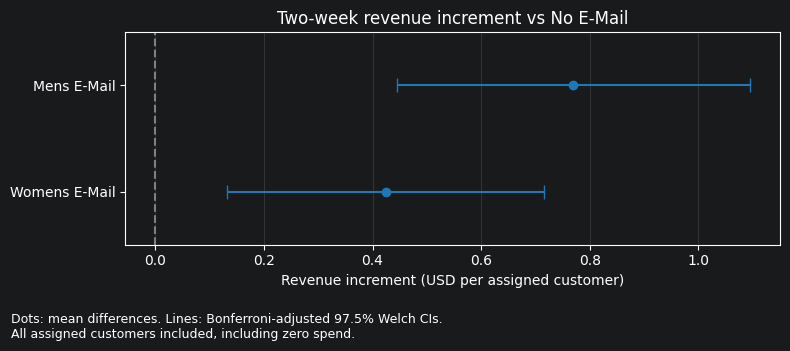

In [91]:
import matplotlib.pyplot as plt

revenue_points = revenue_plot_data["revenue_difference"]

revenue_xerr = np.vstack([
    revenue_points - revenue_plot_data["ci_low"],
    revenue_plot_data["ci_high"] - revenue_points,
])

revenue_y = np.arange(len(revenue_plot_data))

revenue_fig, revenue_ax = plt.subplots(figsize=(8, 3.5))

revenue_ax.errorbar(
    x=revenue_points,
    y=revenue_y,
    xerr=revenue_xerr,
    fmt="o",
    capsize=5,
    color="tab:blue",
)

revenue_ax.axvline(0, color="gray", linestyle="--")

revenue_ax.set_yticks(
    revenue_y,
    labels=revenue_plot_data["treatment"],
)
revenue_ax.set_ylim(-0.5, len(revenue_plot_data) - 0.5)
revenue_ax.invert_yaxis()

revenue_ax.set_xlabel("Revenue increment (USD per assigned customer)")
revenue_ax.set_title("Two-week revenue increment vs No E-Mail")
revenue_ax.grid(axis="x", alpha=0.25)

revenue_fig.text(
    0.02, 0.02,
    "Dots: mean differences. Lines: Bonferroni-adjusted 97.5% Welch CIs.\n"
    "All assigned customers included, including zero spend.",
    fontsize=9,
)

revenue_fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

In [92]:
practice_output_dir = project_root / "reports" / "practice"
practice_output_dir.mkdir(parents=True, exist_ok=True)

revenue_csv_path = (
    practice_output_dir / "revenue_increment_bonferroni.csv"
)
revenue_png_path = (
    practice_output_dir / "revenue_increment_bonferroni.png"
)

revenue_plot_data.to_csv(
    revenue_csv_path,
    index=False,
    encoding="utf-8-sig",
)

revenue_fig.savefig(
    revenue_png_path,
    dpi=200,
    bbox_inches="tight",
    facecolor=revenue_fig.get_facecolor(),
    transparent=False,
)

print("数据表保存位置：", revenue_csv_path.resolve())
print("图片保存位置：", revenue_png_path.resolve())